# 条形图

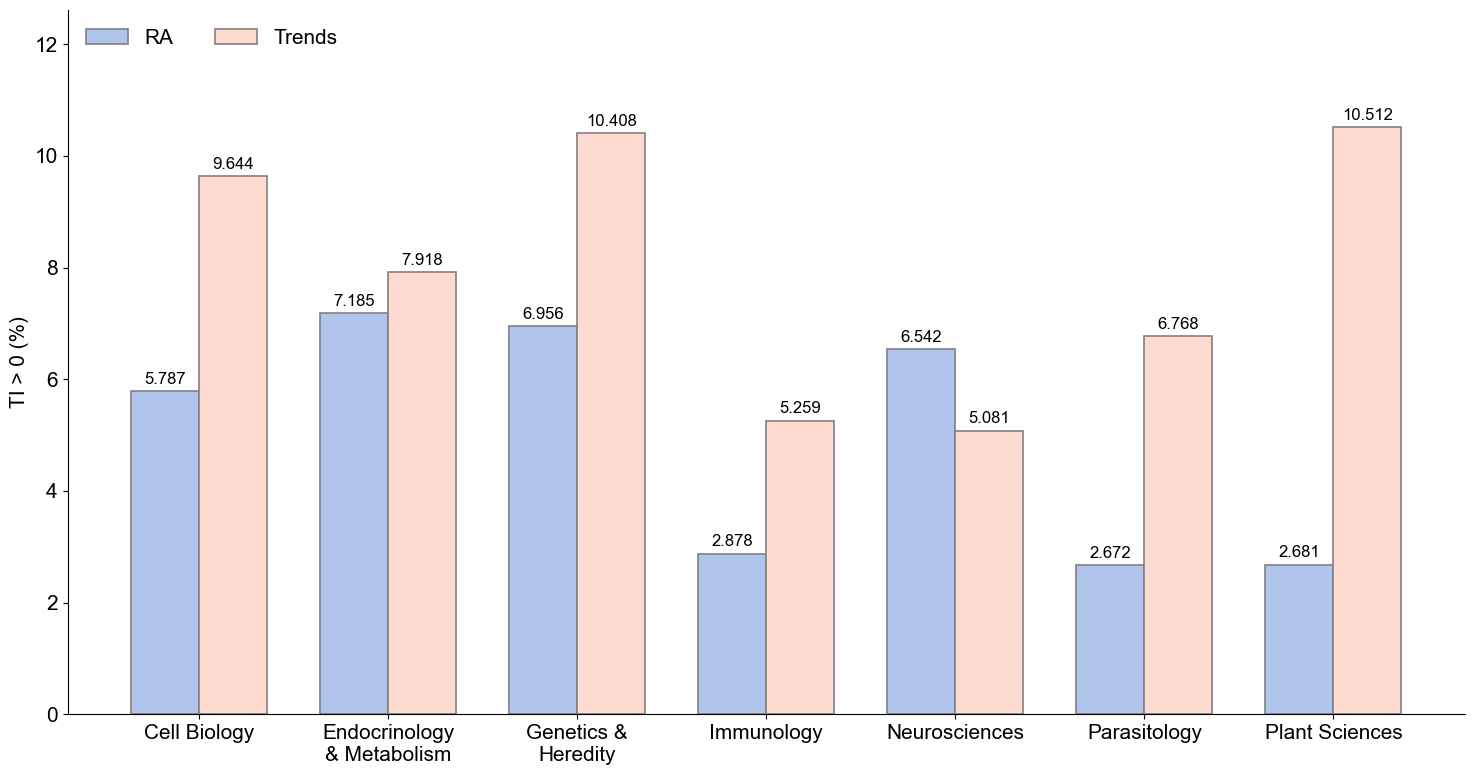

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


categories = [
    "Cell Biology",
    "Endocrinology\n& Metabolism",
    "Genetics &\nHeredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
]

ra = [5.787, 7.185, 6.956, 2.878, 6.542, 2.672, 2.681]
trends = [9.644, 7.918, 10.408, 5.259, 5.081, 6.768, 10.512]

# 字体与导出设置
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

x = np.arange(len(categories))
width = 0.36

fig, ax = plt.subplots(figsize=(15, 8))

# 分组柱状图
bars_ra = ax.bar(
    x - width / 2, ra, width,
    label="RA", 
    color="#B1C4EB",
    edgecolor="#808080",
    linewidth=1.2
)
bars_trends = ax.bar(
    x + width / 2, trends, width,
    label="Trends", 
    color="#FEDBD0",
    edgecolor="#808080",
    linewidth=1.2
)

# 柱顶数值
ax.bar_label(bars_ra, fmt="%.3f", padding=3, fontsize=12)
ax.bar_label(bars_trends, fmt="%.3f", padding=3, fontsize=12)

# 坐标轴与图例
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=15)
# ax.set_xlabel("WOS Category")
ax.set_ylabel("TI > 0 (%)")
ax.set_ylim(0, max(ra + trends) * 1.20)
ax.set_yticks(np.arange(0, 13, 2))
ax.legend(loc="upper left", ncol=2, frameon=False)

fig.tight_layout()

# 保存到脚本所在文件夹；Notebook 中则保存到当前目录
output_dir = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd()
)
fig.savefig(output_dir / "bar_chart.png", dpi=600, bbox_inches="tight")
fig.savefig(output_dir / "bar_chart.pdf", bbox_inches="tight")
fig.savefig(output_dir / "bar_chart.svg", bbox_inches="tight")

plt.show()

# 差值条形图

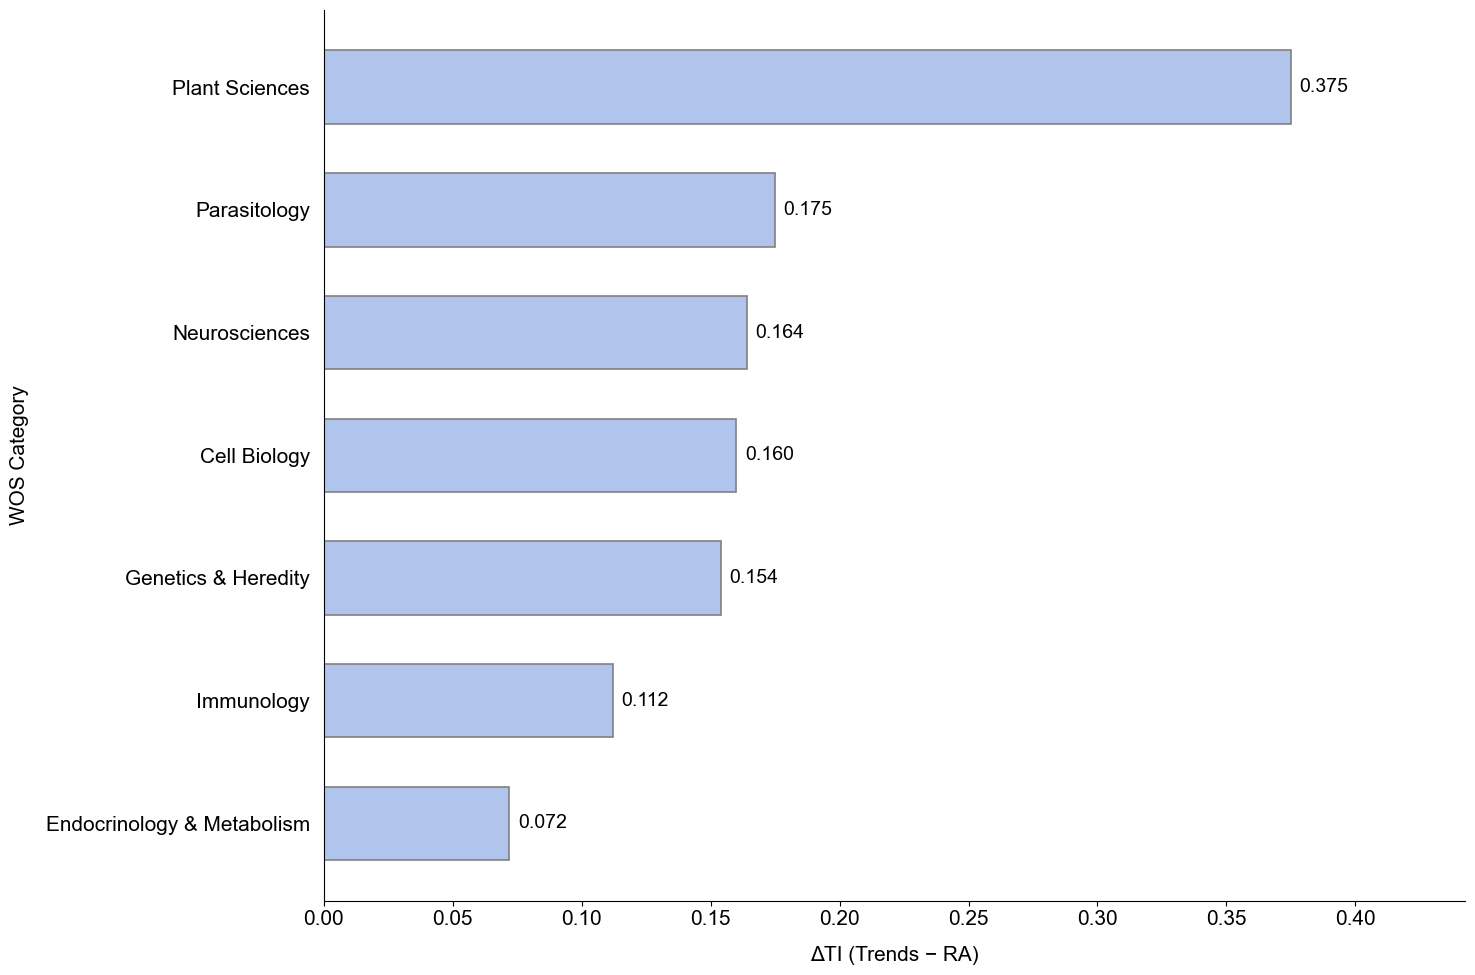

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# 原始数据
categories = np.array([
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
])

ra = np.array([
    -0.295, -0.254, -0.233, -0.270,
    -0.212, -0.454, -0.389
])

trends = np.array([
    -0.135, -0.182, -0.079, -0.158,
    -0.048, -0.279, -0.014
])

# 计算差值，并按差值从大到小排序
delta = trends - ra
order = np.argsort(-delta)

sorted_categories = categories[order]
sorted_delta = delta[order]

# 字体与导出设置
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

fig, ax = plt.subplots(figsize=(15, 10))
y = np.arange(len(sorted_categories))

# 横向差值条形图
bars = ax.barh(
    y,
    sorted_delta,
    height=0.60,
    color="#B1C4EB",
    edgecolor="#808080",
    linewidth=1.2
)

# 条形末端标注三位小数
ax.bar_label(
    bars,
    fmt="%.3f",
    padding=6,
    fontsize=14
)

# 学科标签，最大差值位于最上方
ax.set_yticks(y)
ax.set_yticklabels(sorted_categories)
ax.invert_yaxis()

# 坐标轴：差值从 0 开始，右侧为数值标签留白
ax.set_xlabel("ΔTI (Trends − RA)", labelpad=12)
ax.set_ylabel("WOS Category", labelpad=12)
ax.set_xlim(0, sorted_delta.max() * 1.18)
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.tick_params(axis="y", length=0, pad=10)

fig.tight_layout()

# 如需保存图片，取消下面几行的注释
# output_dir = (
#     Path(__file__).resolve().parent
#     if "__file__" in globals()
#     else Path.cwd()
# )
# fig.savefig(output_dir / "ti_difference.png", dpi=600)
# fig.savefig(output_dir / "ti_difference.pdf")
# fig.savefig(output_dir / "ti_difference.svg")

plt.show()

# 哑铃图

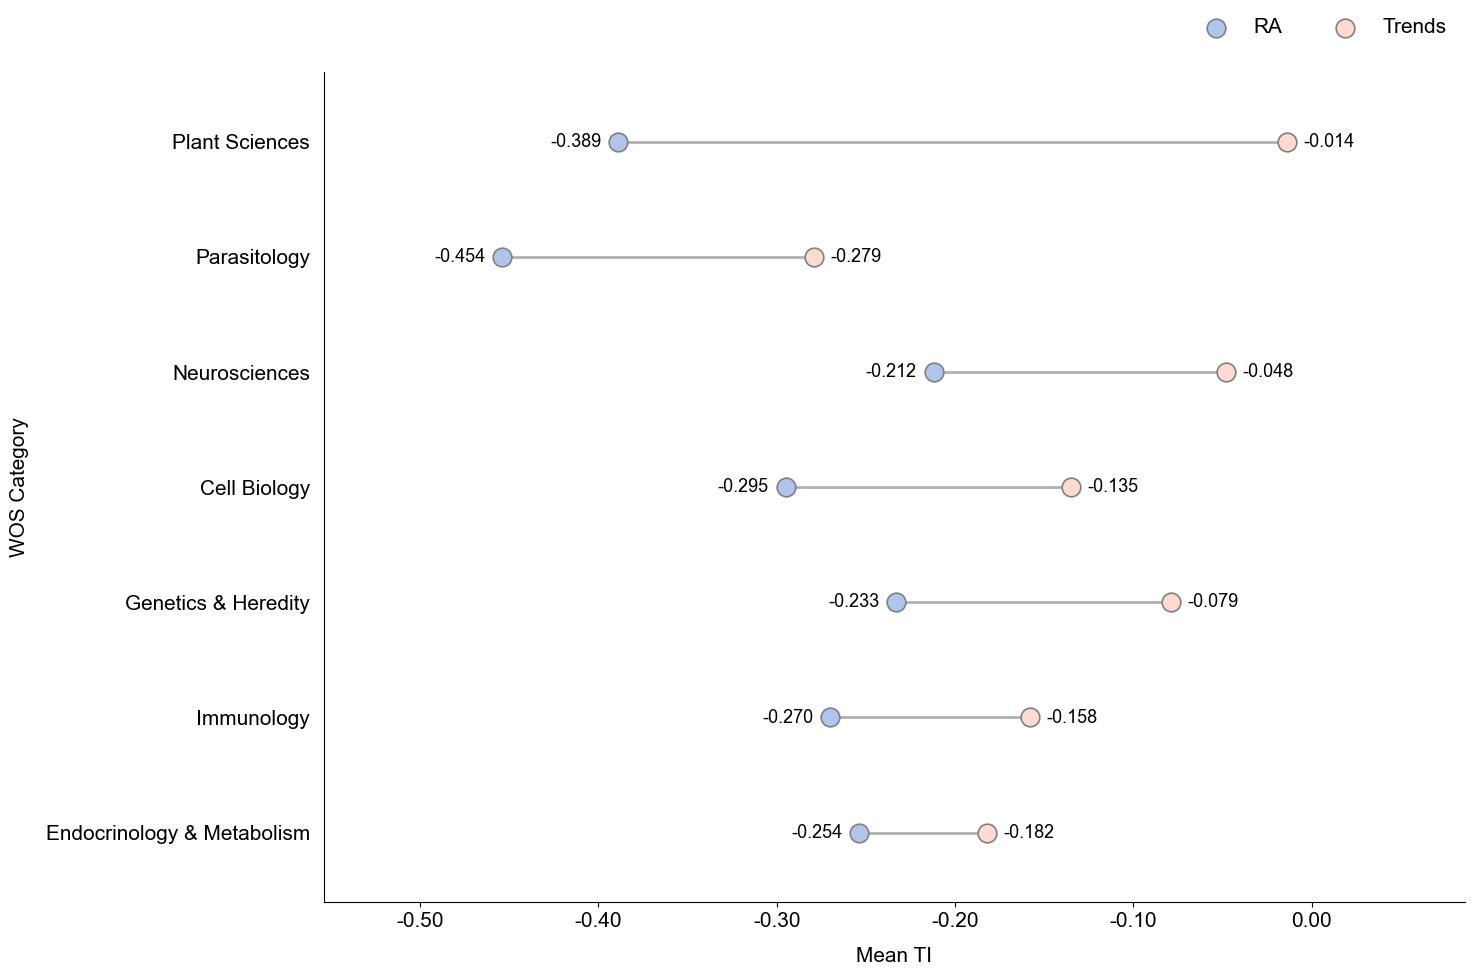

In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# 原始数据
categories = np.array([
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
])

ra = np.array([
    -0.295, -0.254, -0.233, -0.270,
    -0.212, -0.454, -0.389
])

trends = np.array([
    -0.135, -0.182, -0.079, -0.158,
    -0.048, -0.279, -0.014
])

# 按差值从大到小排序
order = np.argsort(-(trends - ra))

categories = categories[order]
ra = ra[order]
trends = trends[order]
y = np.arange(len(categories))

# 字体与导出设置
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

fig, ax = plt.subplots(figsize=(15, 10))

# 连接同一学科的两个数值
ax.hlines(
    y=y,
    xmin=ra,
    xmax=trends,
    color="#B0B0B0",
    linewidth=2,
    zorder=1
)

# RA：浅蓝色圆点
ax.scatter(
    ra, y,
    s=180,
    color="#B1C4EB",
    edgecolors="#808080",
    linewidths=1.2,
    label="RA",
    zorder=3
)

# Trends：浅橙色圆点
ax.scatter(
    trends, y,
    s=180,
    color="#FEDBD0",
    edgecolors="#808080",
    linewidths=1.2,
    label="Trends",
    zorder=3
)

# 数值标签：RA 放左侧，Trends 放右侧
for yi, ra_value, trends_value in zip(y, ra, trends):
    ax.annotate(
        f"{ra_value:.3f}",
        xy=(ra_value, yi),
        xytext=(-12, 0),
        textcoords="offset points",
        ha="right",
        va="center",
        fontsize=13
    )

    ax.annotate(
        f"{trends_value:.3f}",
        xy=(trends_value, yi),
        xytext=(12, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=13
    )

# 坐标轴
ax.set_yticks(y)
ax.set_yticklabels(categories)
ax.invert_yaxis()

ax.set_xlabel("Mean TI", labelpad=12)
ax.set_ylabel("WOS Category", labelpad=12)

# 两端留白，避免数值标签被裁切
ax.set_xlim(ra.min() - 0.10, trends.max() + 0.10)
ax.margins(y=0.10)

ax.xaxis.set_major_locator(MultipleLocator(0.10))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.tick_params(axis="y", length=0, pad=10)

ax.legend(
    loc="lower right",
    bbox_to_anchor=(1, 1.02),
    ncol=2,
    frameon=False
)

fig.tight_layout()

# 如需保存图片，取消下面几行的注释
# output_dir = (
#     Path(__file__).resolve().parent
#     if "__file__" in globals()
#     else Path.cwd()
# )
# fig.savefig(output_dir / "ti_dumbbell.png", dpi=600)
# fig.savefig(output_dir / "ti_dumbbell.pdf")
# fig.savefig(output_dir / "ti_dumbbell.svg")

plt.show()

meta NOT subset; don't know how to subset; dropped


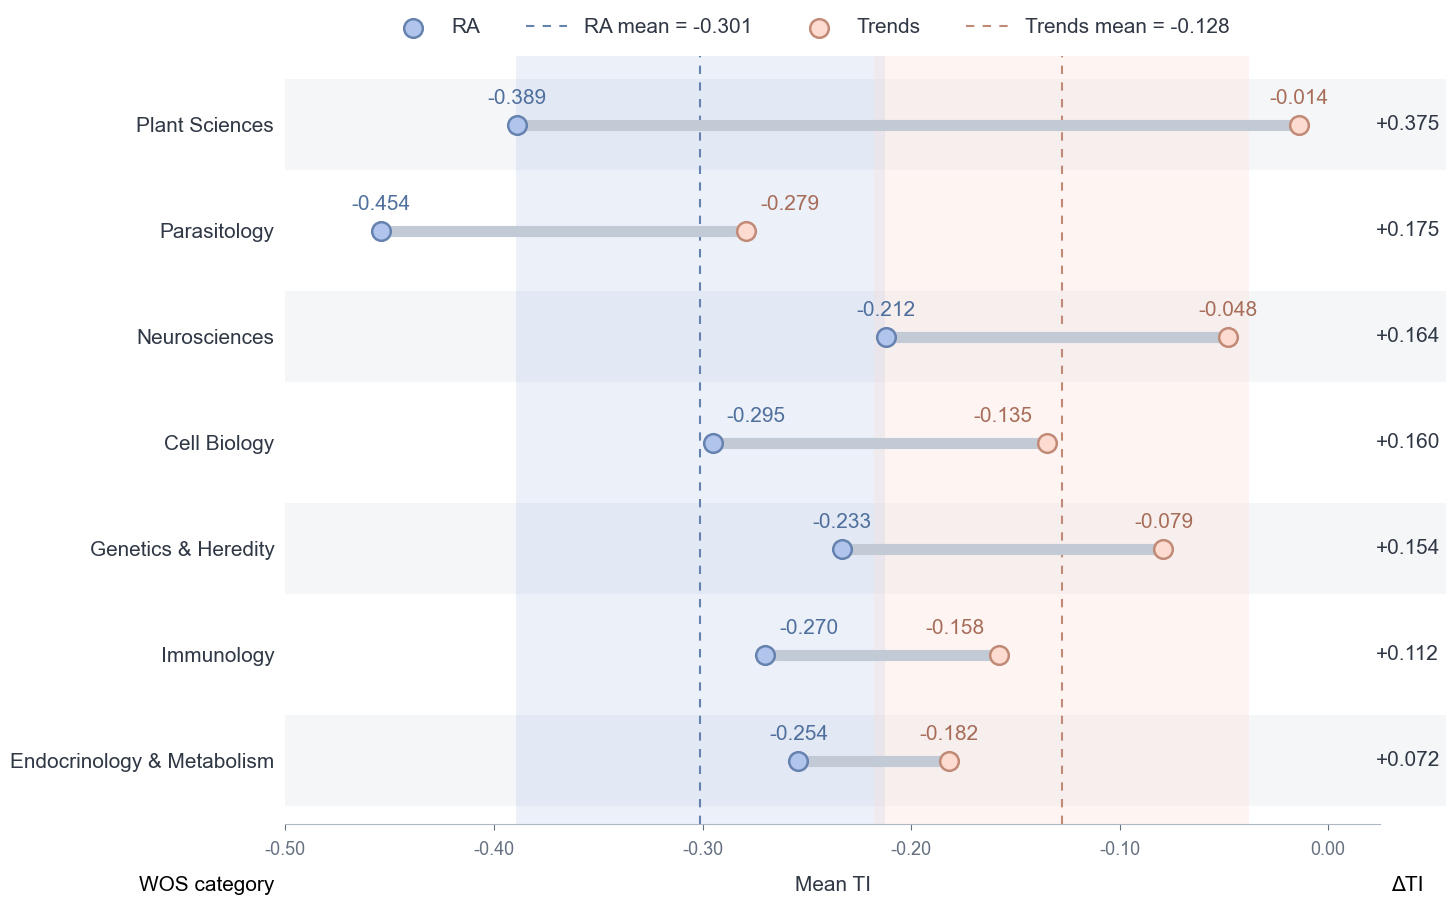

In [7]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# ==================== 数据 ====================
categories = np.array([
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
])

ra = np.array([
    -0.295, -0.254, -0.233, -0.270,
    -0.212, -0.454, -0.389
])

trends = np.array([
    -0.135, -0.182, -0.079, -0.158,
    -0.048, -0.279, -0.014
])

delta = trends - ra

# 两组各自在 7 个学科上的等权均值
ra_mean = ra.mean()
ra_std = ra.std(ddof=1)

trends_mean = trends.mean()
trends_std = trends.std(ddof=1)

# 按差值从大到小排序
# 保留原顺序时，改为：order = np.arange(len(categories))
order = np.argsort(-delta)
categories = categories[order]
ra = ra[order]
trends = trends[order]
delta = delta[order]

y = np.arange(len(categories))

# ==================== 可调整参数 ====================
SHOW_ROW_BACKGROUND = True   # 交替浅灰行背景
SHOW_MEAN_LINES = True       # 两条均值竖线
SHOW_MEAN_BAND = True        # 两个均值之间的背景带
SHOW_VALUE_LABELS = True     # 两端原始数值
SAVE_FIGURE = True          # 是否保存文件

RA_COLOR = "#B1C4EB"
TRENDS_COLOR = "#FEDBD0"
RA_EDGE = "#6683B0"
TRENDS_EDGE = "#C18A76"

LINE_COLOR = "#C2CAD5"
ROW_COLOR = "#F5F6F8"
BAND_COLOR = "#DEE6EF"

# ==================== 字体与画布 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#657080",
    "ytick.color": "#303846",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

fig, ax = plt.subplots(figsize=(15, 12))

# 左侧留给学科名称，右侧留给差值列
fig.subplots_adjust(
    left=0.30,
    right=0.85,
    bottom=0.12,
    top=0.80
)

# ==================== 背景 ====================
# 所有着色行使用同一种浅灰色，不单独突出任何学科
if SHOW_ROW_BACKGROUND:
    for i in y:
        if i % 2 == 0:
            ax.axhspan(
                i - 0.43,
                i + 0.43,
                xmin=0,
                xmax=1.06,
                facecolor=ROW_COLOR,
                edgecolor="none",
                clip_on=False,
                zorder=0
            )

# 两条均值竖线之间的背景带
# 仅表示两组学科均值之间的范围，不表示置信区间
# ==================== 均值 ± 1 SD 背景带 ====================
if SHOW_MEAN_BAND:
    # RA：浅蓝色背景带
    ax.axvspan(
        ra_mean - ra_std,
        ra_mean + ra_std,
        facecolor=RA_COLOR,
        alpha=0.25,
        edgecolor="none",
        zorder=0.5
    )

    # Trends：浅橙色背景带
    ax.axvspan(
        trends_mean - trends_std,
        trends_mean + trends_std,
        facecolor=TRENDS_COLOR,
        alpha=0.25,
        edgecolor="none",
        zorder=0.5
    )


# ==================== 均值竖线 ====================
mean_handles = []

if SHOW_MEAN_LINES:
    ra_mean_line = ax.axvline(
        ra_mean,
        color=RA_EDGE,
        linestyle=(0, (4, 4)),
        linewidth=1.5,
        label=f"RA mean = {ra_mean:.3f}",
        zorder=1
    )

    trends_mean_line = ax.axvline(
        trends_mean,
        color=TRENDS_EDGE,
        linestyle=(0, (4, 4)),
        linewidth=1.5,
        label=f"Trends mean = {trends_mean:.3f}",
        zorder=1
    )

    mean_handles = [ra_mean_line, trends_mean_line]

# ==================== 哑铃连接线 ====================
# 每一行使用相同颜色、相同粗细
for i in y:
    ax.plot(
        [ra[i], trends[i]],
        [i, i],
        color=LINE_COLOR,
        linewidth=8,
        solid_capstyle="round",
        zorder=2
    )

# ==================== 圆形端点 ====================
ra_points = ax.scatter(
    ra, y,
    s=180,
    marker="o",
    facecolors=RA_COLOR,
    edgecolors=RA_EDGE,
    linewidths=1.8,
    label="RA",
    zorder=4
)

trends_points = ax.scatter(
    trends, y,
    s=180,
    marker="o",
    facecolors=TRENDS_COLOR,
    edgecolors=TRENDS_EDGE,
    linewidths=1.8,
    label="Trends",
    zorder=4
)

# ==================== 原始数值标签 ====================
def add_value_label(value, row, color):
    """标签放在圆点上方；靠近均值竖线时，向远离竖线的一侧偏移。"""
    offset_x = 0
    alignment = "center"

    if SHOW_MEAN_LINES:
        means = np.array([ra_mean, trends_mean])
        nearest_mean = means[np.argmin(np.abs(means - value))]

        if abs(value - nearest_mean) < 0.035:
            if value >= nearest_mean:
                offset_x = 10
                alignment = "left"
            else:
                offset_x = -10
                alignment = "right"

    ax.annotate(
        f"{value:.3f}",
        xy=(value, row),
        xytext=(offset_x, 12),
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=15,
        color=color,
        zorder=5
    )


if SHOW_VALUE_LABELS:
    for i in y:
        add_value_label(ra[i], i, "#4F6F9D")
        add_value_label(trends[i], i, "#A76D59")

# 统一控制右侧差值数字及其标题的位置
DELTA_X = 1.025

# ==================== 右侧差值列 ====================
# 所有差值使用相同样式，不加粗或突出第一行


for i in y:
    ax.text(
        DELTA_X,
        i,
        f"{delta[i]:+.3f}",
        transform=ax.get_yaxis_transform(),
        ha="center",
        va="center",
        fontsize=15,
        color="#303846",
        clip_on=False
    )
# ==================== 坐标轴 ====================
ax.set_yticks(y)
ax.set_yticklabels(categories)

# 最大差值位于最上方
ax.set_ylim(len(categories) - 0.40, -0.65)
ax.set_xlim(-0.50, 0.025)

ax.set_xlabel("Mean TI", labelpad=14)

footer_y = -0.08

ax.text(
    -0.01, footer_y,
    "WOS category",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=15,
    color="#000000",
    clip_on=False
)

ax.text(
    DELTA_X, footer_y,
    "ΔTI",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=15,
    color="#000000",
    clip_on=False
)

# 横轴标题与左右列标题对齐
ax.xaxis.set_label_coords(0.50, footer_y)
ax.xaxis.label.set_verticalalignment("center")

# 给底部文字留出空间
fig.subplots_adjust(
    left=0.20,      # 原来 0.30，缩小学科名称区域
    right=0.93,     # 原来 0.85，让绘图区向右扩展
    bottom=0.16,
    top=0.80
)


ax.tick_params(axis="y", length=0, pad=8)
ax.tick_params(axis="x", labelsize=13, length=4, pad=8)

ax.xaxis.set_major_locator(MultipleLocator(0.10))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.spines["bottom"].set_color("#AEB7C3")

# ==================== 图例 ====================
if SHOW_MEAN_LINES:
    # 两列：第一列 RA 及其均值，第二列 Trends 及其均值
    legend_handles = [
        ra_points, mean_handles[0],
        trends_points, mean_handles[1]
    ]
else:
    legend_handles = [ra_points, trends_points]

ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.48, 1),        # 调整图例与图片正文的距离
    ncol=len(legend_handles),
    frameon=False,
    fontsize=15,
    handletextpad=0.8,
    columnspacing=2.2,
    labelspacing=1.0
)


# # ==================== 可选保存 ====================
if SAVE_FIGURE:
    output_dir = (
        Path(__file__).resolve().parent
        if "__file__" in globals()
        else Path.cwd()
    )

    fig.savefig(output_dir / "ti_dumbbell.png", dpi=600, bbox_inches="tight")
    fig.savefig(output_dir / "ti_dumbbell.pdf", bbox_inches="tight")
    fig.savefig(output_dir / "ti_dumbbell.svg", bbox_inches="tight")

plt.show()

# 热力图

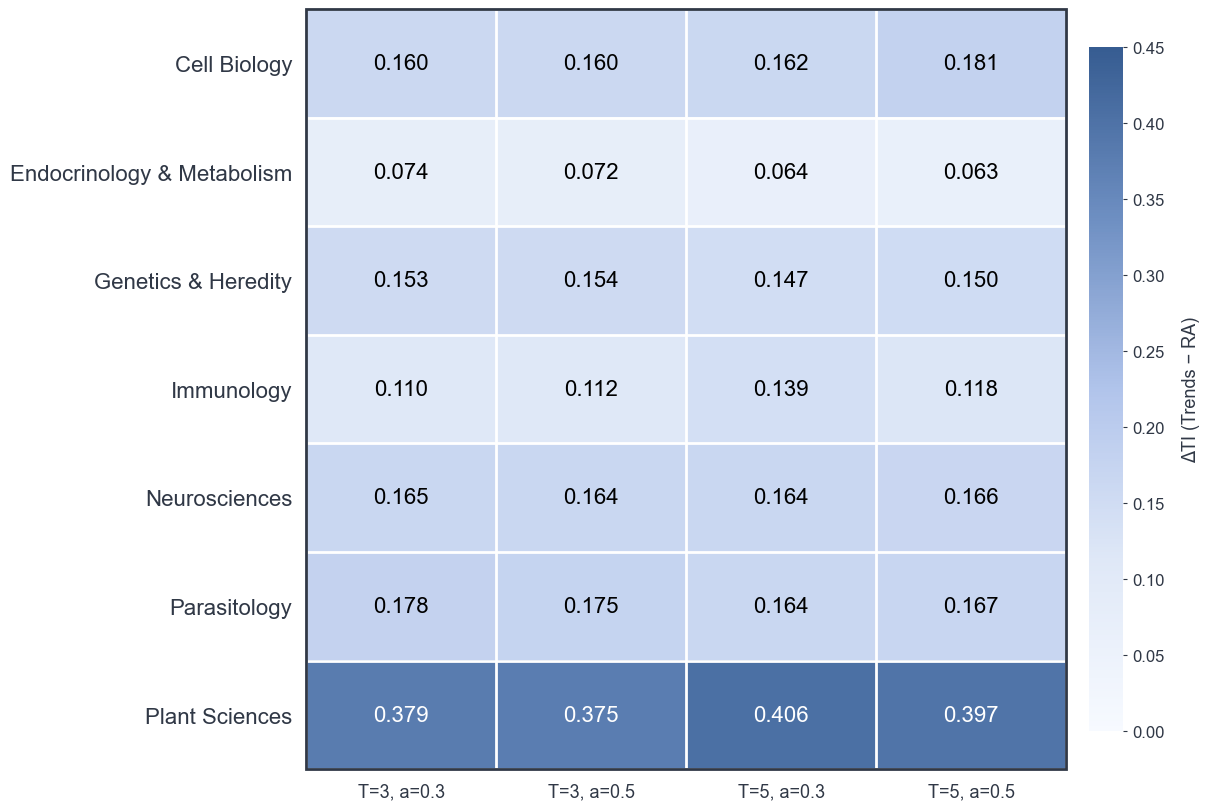

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FormatStrFormatter
from matplotlib.patches import Rectangle

# ==================== 数据 ====================
categories = [
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
]

# 列顺序与最新表格一致
parameter_labels = [
    "T=3, a=0.3",
    "T=3, a=0.5",
    "T=5, a=0.3",
    "T=5, a=0.5",
]

# 每行对应一个学科，每列对应一种参数组合
ra = np.array([
    [-0.296, -0.295, -0.305, -0.321],  # Cell Biology
    [-0.258, -0.254, -0.268, -0.261],  # Endocrinology & Metabolism
    [-0.232, -0.233, -0.231, -0.232],  # Genetics & Heredity
    [-0.272, -0.270, -0.301, -0.276],  # Immunology
    [-0.213, -0.212, -0.215, -0.214],  # Neurosciences
    [-0.459, -0.454, -0.455, -0.462],  # Parasitology
    [-0.391, -0.389, -0.414, -0.409],  # Plant Sciences
])

trends = np.array([
    [-0.136, -0.135, -0.143, -0.140],
    [-0.184, -0.182, -0.204, -0.198],
    [-0.079, -0.079, -0.084, -0.082],
    [-0.162, -0.158, -0.162, -0.158],
    [-0.048, -0.048, -0.051, -0.048],
    [-0.281, -0.279, -0.291, -0.295],
    [-0.012, -0.014, -0.008, -0.012],
])

# 计算差值；单位为 TI，不是百分比
delta = trends - ra

# ==================== 可调整参数 ====================
FIGSIZE = (12, 8)
FONT_SIZE = 16
ANNOTATION_SIZE = 16
SAVE_FIGURE = False

# ==================== 字体与导出设置 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#303846",
    "ytick.color": "#303846",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

# 延续前面的蓝色配色，由浅到深表示差值增大
cmap = LinearSegmentedColormap.from_list(
    "ti_difference_blue",
    [
        "#F7FAFF",
        "#DFE8F7",
        "#B1C4EB",
        "#6E8FC2",
        "#365C91",
    ]
)

# ==================== 绘制热力图 ====================
fig, ax = plt.subplots(
    figsize=FIGSIZE,
    layout="constrained"
)

# 本组差值全部为正，色条从 0 开始
# 上限向上取整至 0.05 的倍数，本组数据得到 0.45
vmax = np.ceil(delta.max() / 0.05) * 0.05

heatmap = ax.imshow(
    delta,
    cmap=cmap,
    vmin=0,
    vmax=vmax,
    aspect="auto",
    interpolation="nearest"
)

# ==================== 坐标轴 ====================
ax.set_xticks(np.arange(len(parameter_labels)))
ax.set_xticklabels(parameter_labels, fontsize=13)

ax.set_yticks(np.arange(len(categories)))
ax.set_yticklabels(categories, fontsize=FONT_SIZE)

# ax.set_xlabel("Parameter setting", labelpad=12)
# ax.set_ylabel("WOS category", labelpad=14)

# ax.set_title(
#     "Mean TI difference across parameter settings",
#     fontsize=16,
#     pad=16
# )

ax.tick_params(axis="both", which="major", length=0, pad=10)

# 白色单元格分隔线
ax.set_xticks(
    np.arange(-0.5, len(parameter_labels), 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, len(categories), 1),
    minor=True
)
ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2
)
ax.tick_params(which="minor", bottom=False, left=False)

for spine in ax.spines.values():
    spine.set_visible(False)

# ==================== 单元格数值 ====================
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        value = delta[i, j]

        # 根据背景颜色选择对比度更高的黑色或白色文字
        rgb = np.array(cmap(heatmap.norm(value))[:3])
        # linear_rgb = np.where(
        #     rgb <= 0.04045,
        #     rgb / 12.92,
        #     ((rgb + 0.055) / 1.055) ** 2.4
        # )
        linear_rgb = np.where(
            rgb <= 0.04045,
            rgb / 12.92,
            ((rgb + 0.055) / 1.055) ** 2.4
        )
        luminance = np.dot(
            linear_rgb,
            [0.2126, 0.7152, 0.0722]
        )
        text_color = "black" if luminance > 0.25 else "white"

        ax.text(
            j, i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=ANNOTATION_SIZE,
            color=text_color
        )

# ==================== 最外层边框 ====================
ax.add_patch(
    Rectangle(
        (-0.5, -0.5),
        len(parameter_labels),
        len(categories),
        fill=False,
        edgecolor="#303846",
        linewidth=2,
        zorder=10,
        clip_on=False,
    )
)

# ==================== 色条 ====================
cbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

cbar.set_label(
    "ΔTI (Trends − RA)",
    fontsize=13,
    labelpad=12
)
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
cbar.ax.tick_params(labelsize=12, length=3)
cbar.outline.set_visible(False)

# # ==================== 可选保存 ====================
# if SAVE_FIGURE:
#     output_dir = (
#         Path(__file__).resolve().parent
#         if "__file__" in globals()
#         else Path.cwd()
#     )

#     fig.savefig(output_dir / "ti_parameter_heatmap.png", dpi=600)
#     fig.savefig(output_dir / "ti_parameter_heatmap.pdf")
#     fig.savefig(output_dir / "ti_parameter_heatmap.svg")

plt.show()

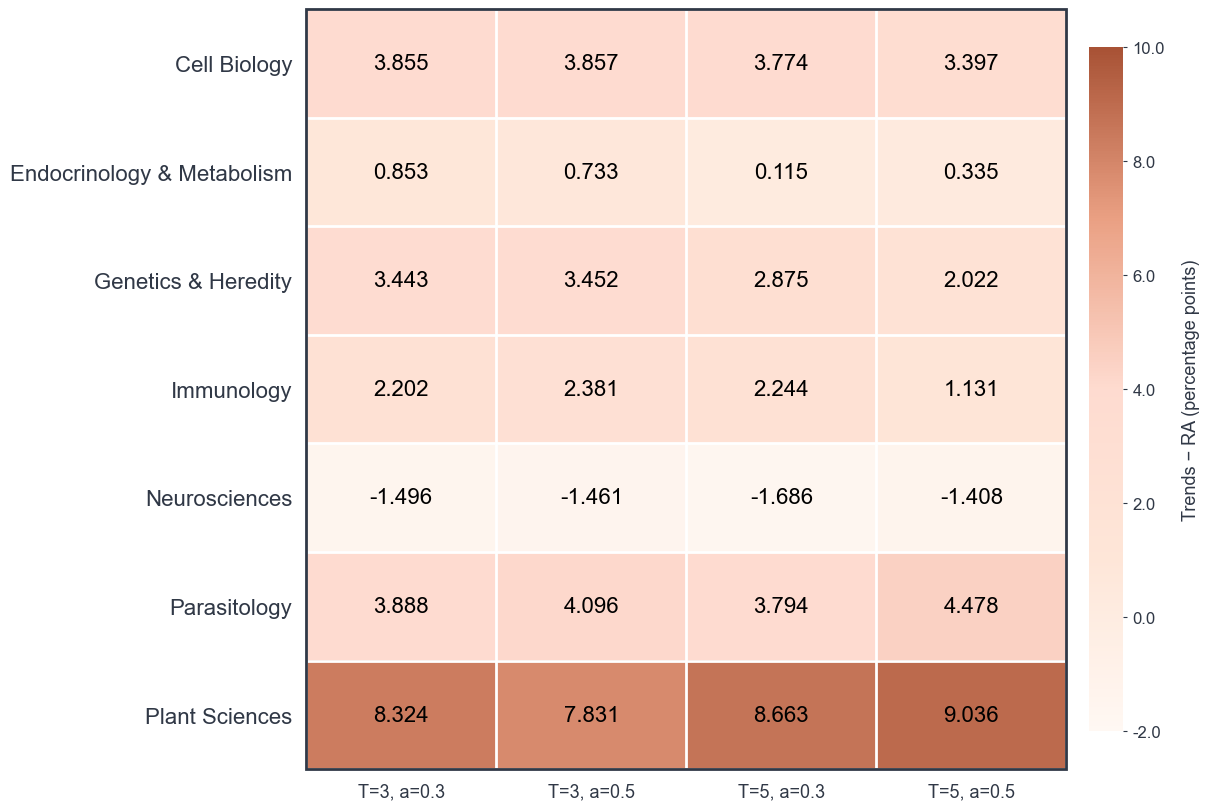

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, Normalize
from matplotlib.ticker import FormatStrFormatter
from matplotlib.patches import Rectangle

# ==================== 数据 ====================
categories = [
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
]

# 与前一张均值热力图保持一致
parameter_labels = [
    "T=3, a=0.3",
    "T=3, a=0.5",
    "T=5, a=0.3",
    "T=5, a=0.5",
]

# 原始数据已经是百分比，无需再乘以 100
ra = np.array([
    [5.899, 5.787, 6.402, 6.027],  # Cell Biology
    [7.191, 7.185, 7.750, 7.195],  # Endocrinology & Metabolism
    [7.031, 6.956, 7.042, 7.261],  # Genetics & Heredity
    [2.734, 2.878, 2.732, 2.819],  # Immunology
    [6.734, 6.542, 7.056, 6.489],  # Neurosciences
    [2.963, 2.672, 2.268, 2.246],  # Parasitology
    [2.879, 2.681, 2.615, 2.456],  # Plant Sciences
])

trends = np.array([
    [9.754, 9.644, 10.176, 9.424],
    [8.044, 7.918, 7.865, 7.530],
    [10.474, 10.408, 9.917, 9.283],
    [4.936, 5.259, 4.976, 3.950],
    [5.238, 5.081, 5.370, 5.081],
    [6.851, 6.768, 6.062, 6.724],
    [11.203, 10.512, 11.278, 11.492],
])

# 百分比相减，得到百分点差
delta = trends - ra

# ==================== 可调整参数 ====================
FIGSIZE = (12, 8)
FONT_SIZE = 16
ANNOTATION_SIZE = 16
SAVE_FIGURE = False

# ==================== 字体与导出设置 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#303846",
    "ytick.color": "#303846",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

# 橙色渐变：差值越大，颜色越深
cmap = LinearSegmentedColormap.from_list(
    "share_difference_orange",
    [
        "#FFF8F3",
        "#FEE6D8",
        "#FEDBD0",
        "#EAA083",
        "#A85235",
    ]
)

# 保留真实负值，本组数据得到 -2 至 10
vmin = np.floor(delta.min())
vmax = np.ceil(delta.max())

# 使用统一的线性色标
norm = Normalize(
    vmin=vmin,
    vmax=vmax
)

# # 正负色标范围对称，便于比较差值大小
# # 本组数据的范围设为 -10 到 +10 个百分点
# color_limit = max(1.0, np.ceil(np.abs(delta).max()))

# norm = TwoSlopeNorm(
#     vmin=-color_limit,
#     vcenter=0,
#     vmax=color_limit
# )

# ==================== 绘制热力图 ====================
fig, ax = plt.subplots(
    figsize=FIGSIZE,
    layout="constrained"
)

heatmap = ax.imshow(
    delta,
    cmap=cmap,
    norm=norm,
    aspect="auto",
    interpolation="nearest"
)

# ==================== 坐标轴 ====================
ax.set_xticks(np.arange(len(parameter_labels)))
ax.set_xticklabels(parameter_labels, fontsize=13)

ax.set_yticks(np.arange(len(categories)))
ax.set_yticklabels(categories, fontsize=FONT_SIZE)

# ax.set_xlabel("Parameter setting", labelpad=12)
# ax.set_ylabel("WOS category", labelpad=14)

# ax.set_title(
#     "Difference in share of papers with TI > 0",
#     fontsize=16,
#     pad=16
# )

ax.tick_params(axis="both", which="major", length=0, pad=10)

# 白色单元格分隔线
ax.set_xticks(
    np.arange(-0.5, len(parameter_labels), 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, len(categories), 1),
    minor=True
)
ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=2
)
ax.tick_params(which="minor", bottom=False, left=False)

for spine in ax.spines.values():
    spine.set_visible(False)

# ==================== 单元格数值 ====================
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        value = delta[i, j]

        # 根据背景颜色选择对比度更高的黑色或白色文字
        rgb = np.array(cmap(norm(value))[:3])
        linear_rgb = np.where(
            rgb <= 0.04045,
            rgb / 12.92,
            ((rgb + 0.055) / 1.055) ** 2.4
        )
        luminance = np.dot(
            linear_rgb,
            [0.2126, 0.7152, 0.0722]
        )
        text_color = "black" if luminance > 0.179 else "white"

        ax.text(
            j, i,
            f"{value:.3f}",  # 同时显示正负号，保留三位小数
            ha="center",
            va="center",
            fontsize=ANNOTATION_SIZE,
            color=text_color
        )

# ==================== 最外层边框 ====================
ax.add_patch(
    Rectangle(
        (-0.5, -0.5),
        len(parameter_labels),
        len(categories),
        fill=False,
        edgecolor="#303846",
        linewidth=2,
        zorder=10,
        clip_on=False,
    )
)

# ==================== 色条 ====================
cbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

cbar.set_label(
    "Trends − RA (percentage points)",
    fontsize=13,
    labelpad=12
)

cbar.set_ticks(np.linspace(vmin, vmax, 7))
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
cbar.ax.tick_params(labelsize=12, length=3)
cbar.outline.set_visible(False)

# ==================== 可选保存 ====================
# if SAVE_FIGURE:
#     output_dir = (
#         Path(__file__).resolve().parent
#         if "__file__" in globals()
#         else Path.cwd()
#     )

#     fig.savefig(output_dir / "positive_share_heatmap.png", dpi=600)
#     fig.savefig(output_dir / "positive_share_heatmap.pdf")
#     fig.savefig(output_dir / "positive_share_heatmap.svg")

plt.show()

# 堆叠柱状图

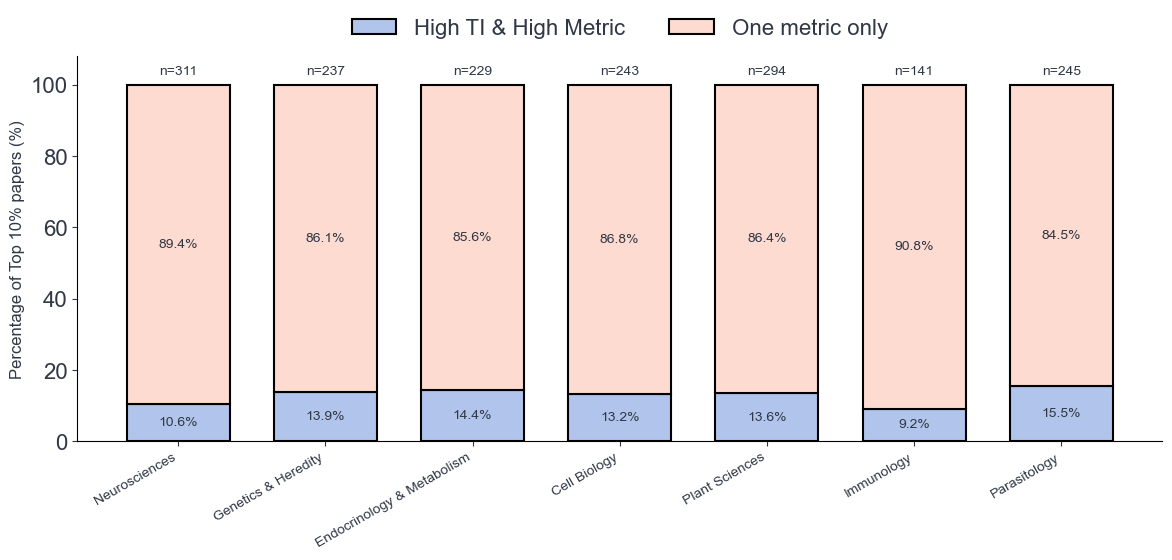

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# =========================
# 1. 数据
# =========================
data = {
    "WoS field": [
        "Neurosciences",
        "Genetics & Heredity",
        "Endocrinology & Metabolism",
        "Cell Biology",
        "Plant Sciences",
        "Immunology",
        "Parasitology"
    ],
    "Top10": [311, 237, 229, 243, 294, 141, 245],
    "Both":  [33, 33, 33, 32, 40, 13, 38],
    "One_only": [278, 204, 196, 211, 254, 128, 207]
}

df = pd.DataFrame(data)

# =========================
# 2. 转换为比例
# =========================
df["Both_pct"] = df["Both"] / df["Top10"] * 100
df["One_pct"] = df["One_only"] / df["Top10"] * 100

# =========================
# 3. 配色
# =========================
# 颜色取自你提供的色板
color_both = "#B1C4EB"    # 深一点的蓝色：重点
color_one  = "#FEDBD0"    # 浅粉色：只进入一个指标
color_edge = "black"
color_bg   = "#EBF3F7"    # 浅背景色

# =========================
# 4. 绘图
# =========================
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df))
width = 0.7

# High TI & High Metric
ax.bar(
    x,
    df["Both_pct"],
    width=width,
    color=color_both,
    edgecolor=color_edge,
    linewidth=1.5,
    label="High TI & High Metric"
)

# One metric only
ax.bar(
    x,
    df["One_pct"],
    width=width,
    bottom=df["Both_pct"],
    color=color_one,
    edgecolor=color_edge,
    linewidth=1.5,
    label="One metric only"
)

# =========================
# 5. 在柱子内部标注比例
# =========================
for i in range(len(df)):

    # 双高比例
    ax.text(
        x[i],
        df.loc[i, "Both_pct"] / 2,
        f'{df.loc[i, "Both_pct"]:.1f}%',
        ha="center",
        va="center",
        fontsize=10
    )

    # 单指标比例
    ax.text(
        x[i],
        df.loc[i, "Both_pct"] + df.loc[i, "One_pct"] / 2,
        f'{df.loc[i, "One_pct"]:.1f}%',
        ha="center",
        va="center",
        fontsize=10
    )

    # 柱顶标注 Top10% 实际数量
    ax.text(
        x[i],
        102,
        f'n={df.loc[i, "Top10"]}',
        ha="center",
        va="bottom",
        fontsize=10
    )

# =========================
# 6. 图形美化
# =========================
ax.set_ylim(0, 108)

ax.set_ylabel("Percentage of Top 10% papers (%)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(
    df["WoS field"],
    rotation=30,
    ha="right",
    fontsize=10
)

ax.set_yticks([0, 20, 40, 60, 80, 100])

ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=2
)

# 去掉上、右边框
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

meta NOT subset; don't know how to subset; dropped
meta NOT subset; don't know how to subset; dropped


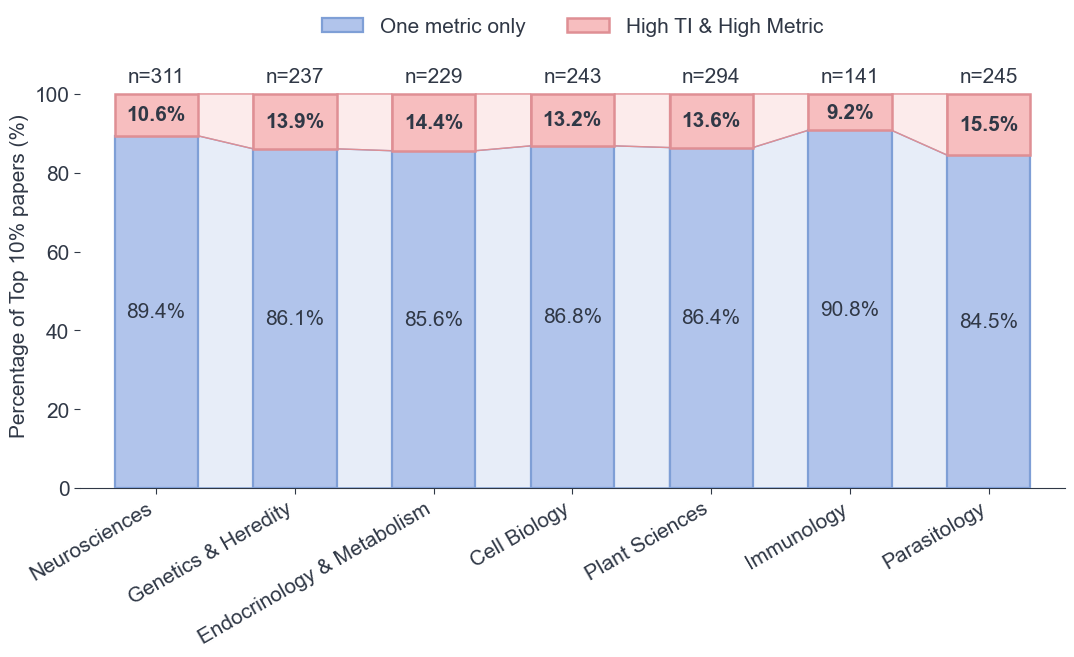

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.patches import Polygon

# ==================== 全局参数 ====================
FONT_SIZE = 15

# ==================== 字体与导出设置 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#303846",
    "ytick.color": "#303846",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})


# ==================== 1. 数据 ====================
data = {
    "WoS field": [
        "Neurosciences",
        "Genetics & Heredity",
        "Endocrinology & Metabolism",
        "Cell Biology",
        "Plant Sciences",
        "Immunology",
        "Parasitology"
    ],

    "Top10": [
        311, 237, 229, 243, 294, 141, 245
    ],

    # 红色顶部：重点关注
    "Both": [
        33, 33, 33, 32, 40, 13, 38
    ],

    # 蓝色底部
    "One_only": [
        278, 204, 196, 211, 254, 128, 207
    ]
}

df = pd.DataFrame(data)


# ==================== 2. 转换为比例 ====================
df["Both_pct"] = df["Both"] / df["Top10"] * 100
df["One_pct"] = df["One_only"] / df["Top10"] * 100


# ==================== 3. 配色 ====================

# 蓝色：底部 One metric only
color_blue = "#B1C4EB"
edge_blue = "#7F9FD6"

# 红色：顶部 High TI & High Metric
color_red = "#F7BEBF"
edge_red = "#DF8F94"

# ribbon 填充透明度
RIBBON_ALPHA = 0.3


# ==================== 4. 建立画布 ====================
fig, ax = plt.subplots(figsize=(11, 7))

x = np.arange(len(df))

# 柱宽
width = 0.6


# ==========================================================
# 5. 相邻柱子之间的连接带 Ribbon
#    注意：先画连接带，再画柱子
# ==========================================================

for i in range(len(df) - 1):

    # 当前柱右边缘
    x1 = x[i] + width / 2

    # 下一根柱左边缘
    x2 = x[i + 1] - width / 2

    # 当前、下一根柱子的蓝色区域高度
    blue_y1 = df.loc[i, "One_pct"]
    blue_y2 = df.loc[i + 1, "One_pct"]


    # --------------------------
    # 蓝色连接区域
    # --------------------------
    blue_vertices = [
        (x1, 0),
        (x2, 0),
        (x2, blue_y2),
        (x1, blue_y1)
    ]

    blue_ribbon = Polygon(
        blue_vertices,
        closed=True,
        facecolor=mcolors.to_rgba(
            color_blue,
            RIBBON_ALPHA
        ),
        edgecolor=edge_blue,
        linewidth=1.0,
        zorder=1
    )

    ax.add_patch(blue_ribbon)


    # --------------------------
    # 红色连接区域
    # --------------------------
    red_vertices = [
        (x1, blue_y1),
        (x2, blue_y2),
        (x2, 100),
        (x1, 100)
    ]

    red_ribbon = Polygon(
        red_vertices,
        closed=True,
        facecolor=mcolors.to_rgba(
            color_red,
            RIBBON_ALPHA
        ),
        edgecolor=edge_red,
        linewidth=1.0,
        zorder=1
    )

    ax.add_patch(red_ribbon)


# ==========================================================
# 6. 正式绘制柱子
# ==========================================================

# --------------------------
# 底部：蓝色
# One metric only
# --------------------------
ax.bar(
    x,
    df["One_pct"],
    width=width,
    color=color_blue,
    edgecolor=edge_blue,
    linewidth=1.6,
    label="One metric only",
    zorder=3
)


# --------------------------
# 顶部：红色
# High TI & High Metric
# --------------------------
ax.bar(
    x,
    df["Both_pct"],
    width=width,
    bottom=df["One_pct"],
    color=color_red,
    edgecolor=edge_red,
    linewidth=1.8,
    label="High TI & High Metric",
    zorder=3
)


# ==========================================================
# 7. 数值标注
# ==========================================================

for i in range(len(df)):

    # --------------------------
    # 蓝色部分比例
    # --------------------------
    ax.text(
        x[i],
        df.loc[i, "One_pct"] / 2,

        f'{df.loc[i, "One_pct"]:.1f}%',

        ha="center",
        va="center",

        fontsize=FONT_SIZE,
        color="#303846",

        zorder=5
    )


    # --------------------------
    # 红色 Both 比例
    # --------------------------
    ax.text(
        x[i],

        df.loc[i, "One_pct"]
        + df.loc[i, "Both_pct"] / 2,

        f'{df.loc[i, "Both_pct"]:.1f}%',

        ha="center",
        va="center",

        fontsize=FONT_SIZE,
        fontweight="bold",
        color="#303846",

        zorder=5
    )


    # --------------------------
    # Top10% 总量
    # --------------------------
    ax.text(
        x[i],
        102,

        f'n={df.loc[i, "Top10"]}',

        ha="center",
        va="bottom",

        fontsize=FONT_SIZE,
        color="#303846",

        zorder=5
    )


# ==========================================================
# 8. 坐标轴
# ==========================================================

ax.set_ylim(0, 108)

# 左右留一点空间
ax.set_xlim(
    -0.55,
    len(df) - 0.45
)

ax.set_ylabel(
    "Percentage of Top 10% papers (%)",
    fontsize=FONT_SIZE
)

ax.set_xticks(x)

ax.set_xticklabels(
    df["WoS field"],
    rotation=30,
    ha="right",
    fontsize=FONT_SIZE
)

ax.set_yticks(
    [0, 20, 40, 60, 80, 100]
)

ax.tick_params(
    axis="both",
    labelsize=FONT_SIZE,
    length=4,
    width=0.8
)


# ==========================================================
# 9. 图例
# ==========================================================

ax.legend(
    frameon=False,

    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),

    ncol=2,

    fontsize=FONT_SIZE
)


# ==========================================================
# 10. 边框
# ==========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#303846")
ax.spines["bottom"].set_color("#303846")

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)



# ==========================================================
# 11. 布局
# ==========================================================

plt.tight_layout()

# ==================== 可选保存 ====================
SAVE_FIGURE = True   # 改成 False 就不保存

if SAVE_FIGURE:
    output_dir = (
        Path(__file__).resolve().parent
        if "__file__" in globals()
        else Path.cwd()
    )

    fig.savefig(output_dir / "top10_ribbon.png", dpi=600, bbox_inches="tight")
    fig.savefig(output_dir / "top10_ribbon.pdf", bbox_inches="tight")
    fig.savefig(output_dir / "top10_ribbon.svg", bbox_inches="tight")

plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.patches import Polygon

# ==================== 全局参数 ====================
FONT_SIZE = 15

# ==================== 字体与导出设置 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": FONT_SIZE,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#303846",
    "ytick.color": "#303846",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})


# ==================== 1. 数据 ====================
data = {
    "WoS field": [
        "Neurosciences",
        "Genetics & Heredity",
        "Endocrinology & Metabolism",
        "Cell Biology",
        "Plant Sciences",
        "Immunology",
        "Parasitology"
    ],

    "Top10": [
        311, 237, 229, 243, 294, 141, 245
    ],

    # 红色顶部：重点关注
    "Both": [
        33, 33, 33, 32, 40, 13, 38
    ],

    # 蓝色底部
    "One_only": [
        278, 204, 196, 211, 254, 128, 207
    ]
}

df = pd.DataFrame(data)


# ==================== 2. 转换为比例 ====================
df["Both_pct"] = df["Both"] / df["Top10"] * 100
df["One_pct"] = df["One_only"] / df["Top10"] * 100


# ==================== 3. 配色 ====================

# 蓝色：底部 One metric only
color_blue = "#B1C4EB"
edge_blue = "#7F9FD6"

# 红色：顶部 High TI & High Metric
color_red = "#FEDBD0"
edge_red = "#E9A6A9"

# ribbon 填充透明度
RIBBON_ALPHA = 0.32


# ==================== 4. 建立画布 ====================
fig, ax = plt.subplots(figsize=(11, 7))

x = np.arange(len(df))

# 柱宽
width = 0.65


# ==========================================================
# 5. 相邻柱子之间的连接带 Ribbon
#    注意：先画连接带，再画柱子
# ==========================================================

for i in range(len(df) - 1):

    # 当前柱右边缘
    x1 = x[i] + width / 2

    # 下一根柱左边缘
    x2 = x[i + 1] - width / 2

    # 当前、下一根柱子的蓝色区域高度
    blue_y1 = df.loc[i, "One_pct"]
    blue_y2 = df.loc[i + 1, "One_pct"]


    # --------------------------
    # 蓝色连接区域
    # --------------------------
    blue_vertices = [
        (x1, 0),
        (x2, 0),
        (x2, blue_y2),
        (x1, blue_y1)
    ]

    blue_ribbon = Polygon(
        blue_vertices,
        closed=True,
        facecolor=mcolors.to_rgba(
            color_blue,
            RIBBON_ALPHA
        ),
        edgecolor=edge_blue,
        linewidth=1.0,
        zorder=1
    )

    ax.add_patch(blue_ribbon)


    # --------------------------
    # 红色连接区域
    # --------------------------
    red_vertices = [
        (x1, blue_y1),
        (x2, blue_y2),
        (x2, 100),
        (x1, 100)
    ]

    red_ribbon = Polygon(
        red_vertices,
        closed=True,
        facecolor=mcolors.to_rgba(
            color_red,
            RIBBON_ALPHA
        ),
        edgecolor=edge_red,
        linewidth=1.0,
        zorder=1
    )

    ax.add_patch(red_ribbon)


# ==========================================================
# 6. 正式绘制柱子
# ==========================================================

# --------------------------
# 底部：蓝色
# One metric only
# --------------------------
ax.bar(
    x,
    df["One_pct"],
    width=width,
    color=color_blue,
    edgecolor=edge_blue,
    linewidth=1.6,
    label="One metric only",
    zorder=3
)


# --------------------------
# 顶部：红色
# High TI & High Metric
# --------------------------
ax.bar(
    x,
    df["Both_pct"],
    width=width,
    bottom=df["One_pct"],
    color=color_red,
    edgecolor=edge_red,
    linewidth=1.8,
    label="High TI & High Metric",
    zorder=3
)


# ==========================================================
# 7. 数值标注
# ==========================================================

for i in range(len(df)):

    # --------------------------
    # 蓝色部分比例
    # --------------------------
    ax.text(
        x[i],
        df.loc[i, "One_pct"] / 2,

        f'{df.loc[i, "One_pct"]:.1f}%',

        ha="center",
        va="center",

        fontsize=FONT_SIZE,
        color="#303846",

        zorder=5
    )


    # --------------------------
    # 红色 Both 比例
    # --------------------------
    ax.text(
        x[i],

        df.loc[i, "One_pct"]
        + df.loc[i, "Both_pct"] / 2,

        f'{df.loc[i, "Both_pct"]:.1f}%',

        ha="center",
        va="center",

        fontsize=FONT_SIZE,
        fontweight="bold",
        color="#303846",

        zorder=5
    )


    # --------------------------
    # Top10% 总量
    # --------------------------
    ax.text(
        x[i],
        102,

        f'n={df.loc[i, "Top10"]}',

        ha="center",
        va="bottom",

        fontsize=FONT_SIZE,
        color="#303846",

        zorder=5
    )


# ==========================================================
# 8. 坐标轴
# ==========================================================

ax.set_ylim(0, 108)

# 左右留一点空间
ax.set_xlim(
    -0.55,
    len(df) - 0.45
)

ax.set_ylabel(
    "Percentage of Top 10% papers (%)",
    fontsize=FONT_SIZE
)

ax.set_xticks(x)

ax.set_xticklabels(
    df["WoS field"],
    rotation=30,
    ha="right",
    fontsize=FONT_SIZE
)

ax.set_yticks(
    [0, 20, 40, 60, 80, 100]
)

ax.tick_params(
    axis="both",
    labelsize=FONT_SIZE,
    length=4,
    width=0.8
)


# ==========================================================
# 9. 图例
# ==========================================================

ax.legend(
    frameon=False,

    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),

    ncol=2,

    fontsize=FONT_SIZE
)


# ==========================================================
# 10. 边框
# ==========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#303846")
ax.spines["bottom"].set_color("#303846")

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)


# ==========================================================
# 11. 布局
# ==========================================================

plt.tight_layout()

plt.show()